In [20]:
import pandas as pandas
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

In [21]:
import os

dataset_path = r"C:\Users\parth\OneDrive\Desktop\NeuroScan AI\Training"

for folder in os.listdir(dataset_path):

    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):

        count = len(os.listdir(folder_path))

        print(folder, count)

glioma 1400
meningioma 1400
notumor 1400
pituitary 1400


In [22]:
img =Image.open("Training/notumor/Tr-no_1.jpg")

In [23]:
print(img)

<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=201x251 at 0x1D7E21279D0>


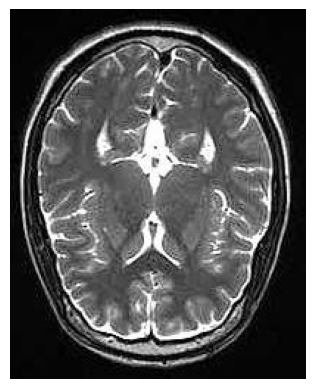

In [24]:
plt.imshow(img, cmap="gray"); 
plt.axis("off"); 
plt.show()

In [25]:
img_array = np.array(img)
print(img_array.shape, img_array.dtype)

(251, 201, 3) uint8


In [ ]:
import numpy as np
from PIL import Image

def features(img):

    # 1. Convert image into grayscale
    grey = np.asarray(
        Image.fromarray(img).convert('L'),
        dtype=float
    )

    # 2. Intensity histogram
    intensity = np.histogram(
        grey,
        bins=32,
        range=(0, 256),
        density=True
    )[0]

    # 3. Edge detection
    edges = np.hypot(
        *np.gradient(grey)
    )

    edge_features = np.histogram(
        edges,
        bins=32,
        density=True
    )[0]

    # 4. Combine features
    return np.concatenate([
        intensity,
        edge_features
   ])

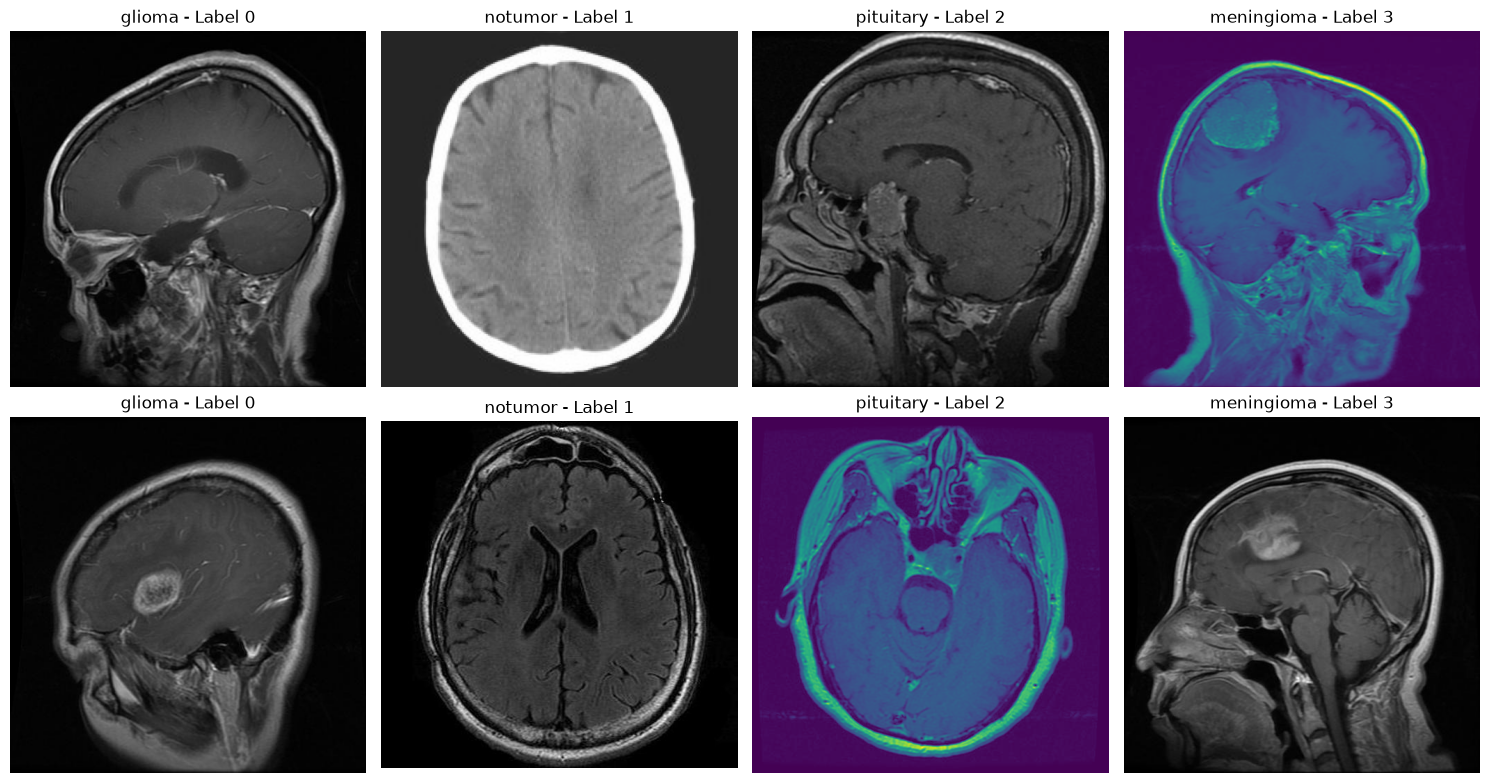

In [40]:
import random
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for i, (folder, label) in enumerate(classes.items()):

    folder_path = os.path.join(dataset_path, folder)

    images = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpeg", ".jpg", ".png"))
    ]

    # Select 2 random images
    random_images = random.sample(images, 2)

    for j, filename in enumerate(random_images):

        image_path = os.path.join(folder_path, filename)

        img = Image.open(image_path)

        axes[j, i].imshow(img)
        axes[j, i].set_title(f"{folder} - Label {label}")
        axes[j, i].axis("off")

plt.tight_layout()
plt.show()

In [28]:
X=[]
Y=[]
dataset_path = r"C:\Users\parth\OneDrive\Desktop\NeuroScan AI\Training"
classes = {
    "glioma": 0,
    "notumor": 1,
    "pituitary": 2,
    "meningioma": 3
}


for folder,label in classes.items():
    folder_path=os.path.join(dataset_path,folder)

    for filename in os.listdir(folder_path):
        if filename.endswith(".jpg"):
            img_path=os.path.join(folder_path,filename)
            img=Image.open(img_path)
            img_array=np.array(img)
            feature_vector=features(img_array)
            X.append(feature_vector)
            Y.append(label)

                             



In [29]:
X = np.array(X)
Y = np.array(Y)

print("X shape:", X.shape)
print("y shape:", Y.shape)

X shape: (5600, 64)
y shape: (5600,)


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.1,
    random_state=42,
    stratify=Y
)

In [33]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create KNN model
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Create 5 folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross validation
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("Fold scores:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold scores: [0.81845238 0.83333333 0.83035714 0.82638889 0.85515873]
Mean accuracy: 0.8327380952380953
Standard deviation: 0.012272751662057227
